# 11 — Cruces del entorno: lo que los factores de la ciudad hacen entre sí

## Pregunta y por qué importa

El cuaderno 09 midió cada factor del entorno de Manizales (clima, calendario, eventos, vigilancia en salud,
seguridad, ENSO) contra la enfermedad de la ciudad. Este cuaderno cruza los factores entre sí y busca la
condición que decide si un efecto aparece: el tipo de día, la temporada, el historial previo de lluvia, el
subgrupo. Importa por dos razones. Primero, el modelo del hospital solo debe recibir variables con un mecanismo
plausible y una medición que lo sostenga, porque con unas 75 semanas independientes útiles (236 semanas con un
residuo semanal de autocorrelación +0,62) cualquier variable de más se ajusta al ruido. Segundo, un efecto
promedio puede esconder uno condicional: la misma lluvia o el mismo frío no tienen que pesar igual un día
laborable que uno de fiesta, ni en la temporada de lluvias que fuera de ella.

El cuaderno no usa datos del hospital. Trabaja con la IRA y la EDA de Manizales (SIVIGILA, semanales), las
denuncias de la Policía (diarias) y el calendario, el clima y el ENSO. Esa restricción tiene un costo que se
retoma en los límites: el mecanismo de la incapacidad (enfermar en día laborable lleva al servicio de
urgencias a pedir la constancia; en fin de semana no necesariamente) opera sobre la consulta del hospital, y
solo se puede aproximar con series semanales de la ciudad.

## Qué se encontró, en una línea por cruce

1. Las fuentes de salud y de la Policía comparten tendencia anual, pero no se siguen semana a semana.
2. Tras la Feria sube la IRA, pero esa ola no se puede atribuir a la Feria; los puentes no mueven la IRA y
   Semana Santa la baja.
3. El frío y la humedad de las cinco semanas previas empujan la IRA entre un 7 y un 10 %, y el efecto se
   concentra en la temporada de lluvias (12,6 % frente a 4,7 % fuera de ella). Los colegios no lo modifican.
4. La lluvia reduce un 5,7 % las lesiones personales; la violencia intrafamiliar no responde al clima. La
   diferencia entre días laborables y no laborables no se distingue.
5. Los eventos de la ciudad no dejan una huella clara en las denuncias.
6. El intento de suicidio tiene su propio año: baja en enero-febrero y sube en agosto-octubre.
7. El ENSO es contexto de fondo; no precede a la IRA ni a la EDA con una señal que supere el azar.
8. La lluvia que llega tras un periodo seco no mueve la EDA de la ciudad a escala semanal.

## De dónde salen los datos

Los mismos archivos del cuaderno 09: SIVIGILA (INS), Policía y Ministerio de Defensa (datos.gov.co), clima
unificado (en su versión con el pluviómetro de La Nubia corregido), ENSO (NOAA), calendario oficial, recesos
escolares por resolución, y eventos y fiestas con fuente. Todo se agrega por semana o por día. La IRA de la
ciudad es la suma de las consultas notificadas por las instituciones de Manizales sin la del hospital de
referencia, y se expresa como anomalía: el logaritmo menos el nivel del año y menos la forma estacional.

In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
import statsmodels.api as sm
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
SES = 170010010301
dias = pd.date_range("2015-01-01", "2026-09-20")
idx = pd.date_range("2015-01-04", "2026-09-13", freq="W-SUN")
def a_semana(s, como="sum"):
    r = getattr(s.resample("W-SAT"), como)(); r.index = r.index - pd.Timedelta(days=6); return r
def anomalia(s):
    s = s.dropna(); s = s - s.groupby(s.index.year).transform("mean")
    return s - s.groupby(s.index.isocalendar().week.values).transform("mean")
def marcar(ini, fin, indice=dias):
    s = pd.Series(0.0, index=indice)
    for a, b in zip(pd.to_datetime(ini), pd.to_datetime(fin)):
        if pd.notna(a): s.loc[a: (b if pd.notna(b) else a)] = 1
    return s

cl = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
oni = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"])
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = np.log(inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")["consultas_ira"].sum().replace(0, np.nan))
vig = pd.concat([pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
                 if "instituciones" not in p.name], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
man = vig[vig.ambito.eq("manizales")].pivot_table(index="fecha_inicio_semana", columns=["evento", "variable"], values="valor", aggfunc="sum")
ev = lambda cod, var="casos_ocurrencia": man[(cod, var)] if (cod, var) in man.columns else None
seg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
calc = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
esc = pd.read_csv(RAIZ / "calendarios/calendario_escolar_manizales.csv", parse_dates=["fecha_inicio", "fecha_fin"])
eventos = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
fiestas = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv")
receso = marcar(esc.fecha_inicio, esc.fecha_fin)
ok_ev = eventos.estado.isin(["realizado", "hibrido"])
feria = marcar(*[eventos[ok_ev & eventos.nombre_evento.eq("Feria de Manizales")][c] for c in ("fecha_inicio", "fecha_fin")])
semana_santa = calc.es_semana_santa.fillna(0)
puente = calc.es_puente.fillna(0)
COVID = ("2020-03-01", "2021-12-31")
def pct(b, s):
    """Efecto en % y su IC95 a partir de un coeficiente logarítmico y su error estándar."""
    return round(100 * (np.exp(b) - 1), 1), f"[{100*(np.exp(b-1.96*s)-1):+.1f}; {100*(np.exp(b+1.96*s)-1):+.1f}]"
print("semanas de IRA de la ciudad:", len(idx), "semanas; IRA ciudad", ira.index.min().date(), "a", ira.index.max().date())

semanas de IRA de la ciudad: 611 semanas; IRA ciudad 2012-01-01 a 2025-12-28


---
# 1. Las fuentes de la ciudad comparten tendencia y no semana

La Policía (denuncias) y el SIVIGILA (notificación de salud) registran fenómenos parecidos por caminos
distintos. Si miden lo mismo, se validan entre sí y basta una de las dos; si no, cada una aporta otra cosa. La
comparación es semanal, en nivel y en anomalía, entre 2015-2019 y 2022-2025, fuera de la COVID.

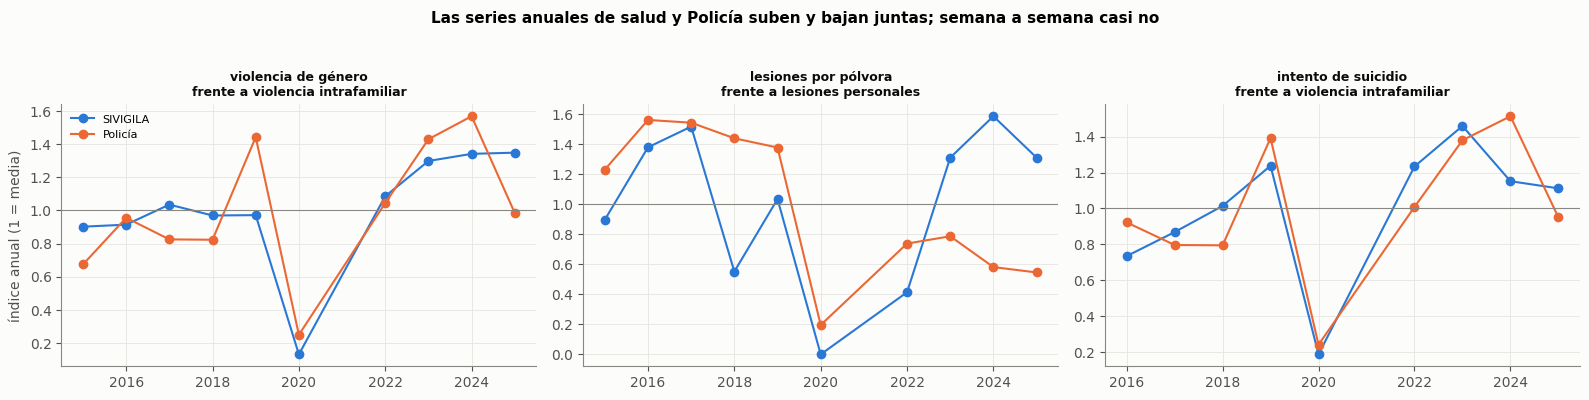

,SIVIGILA,Policía,r semanal (nivel),r semanal (anomalía),r anual,semanas
0,violencia de género (SIVIGILA 875),violencia intrafamiliar (Policía),0.30,0.23,0.79,478
1,lesiones por pólvora (SIVIGILA 452),lesiones personales (Policía),0.09,0.04,0.34,478
2,intento de suicidio (SIVIGILA 356),violencia intrafamiliar (Policía),0.20,0.03,0.86,426


In [2]:
pares = [("violencia de género (SIVIGILA 875)", ev(875), "violencia intrafamiliar (Policía)", a_semana(seg.violencia_intrafamiliar)),
         ("lesiones por pólvora (SIVIGILA 452)", ev(452), "lesiones personales (Policía)", a_semana(seg.lesiones_personales)),
         ("intento de suicidio (SIVIGILA 356)", ev(356), "violencia intrafamiliar (Policía)", a_semana(seg.violencia_intrafamiliar))]
filas = []
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (na, a, nb, b) in zip(axes, pares):
    d = pd.concat([a.rename("a"), b.rename("b")], axis=1).dropna()
    d = d[~d.index.to_series().between(*COVID)]
    anual = d.groupby(d.index.year).sum()
    filas.append({"SIVIGILA": na, "Policía": nb, "r semanal (nivel)": round(d.a.corr(d.b), 2),
                  "r semanal (anomalía)": round(anomalia(d.a).corr(anomalia(d.b)), 2),
                  "r anual": round(anual.a.corr(anual.b), 2), "semanas": len(d)})
    ax.plot(anual.index, anual.a / anual.a.mean(), marker="o", color=AZUL, label="SIVIGILA")
    ax.plot(anual.index, anual.b / anual.b.mean(), marker="o", color=NARANJA, label="Policía")
    ax.set_title(f"{na.split(' (')[0]}\nfrente a {nb.split(' (')[0]}", fontsize=9); ax.axhline(1, color=MUDO, lw=.8)
axes[0].set_ylabel("índice anual (1 = media)"); axes[0].legend(fontsize=8)
fig.suptitle("Las series anuales de salud y Policía suben y bajan juntas; semana a semana casi no", fontsize=11, fontweight="bold", y=1.04)
plt.tight_layout(); plt.show()
pd.DataFrame(filas)

**Lectura.** Cada panel pone en el mismo índice anual (1 = media del periodo) la serie de salud y la de la
Policía. En los tres pares las líneas se parecen en el tiempo, y la tabla muestra que el parecido es de
tendencia y no de semana:

| SIVIGILA | Policía | r semanal | r en anomalía | r anual |
|---|---|---|---|---|
| Violencia de género (875) | Violencia intrafamiliar | 0,30 | 0,23 | 0,79 |
| Lesiones por pólvora (452) | Lesiones personales | 0,09 | 0,04 | 0,34 |
| Intento de suicidio (356) | Violencia intrafamiliar | 0,20 | 0,03 | 0,86 |

- La violencia de género del sector salud y la violencia intrafamiliar de la Policía van juntas año a año
  (0,79) y algo semana a semana (0,23). Miden fenómenos cercanos: una se notifica en la consulta y la otra se
  denuncia.
- El intento de suicidio y la violencia intrafamiliar dan r = 0,86 al año y 0,03 en la semana. Esa correlación
  anual no es un vínculo: las dos series comparten la tendencia de notificación de la década, y semana a
  semana no se tocan.
- La pólvora es demasiado rara (1-2 casos por semana en temporada) para seguir a las lesiones personales.

Una correlación entre series anuales no prueba nada por sí sola, y hay que verificarla en la semana. Donde dos
fuentes miden lo mismo (violencia de género e intrafamiliar), basta una para el modelo.

---
# 2. Después de la Feria sube la IRA, pero la Feria no se puede separar de enero

Mecanismo: reunirse favorece el contagio por contacto, de modo que la IRA debería subir una a tres semanas
después de una aglomeración. La literatura espera un efecto pequeño en las aglomeraciones (infecciones
respiratorias de baja magnitud tras eventos masivos; Van Remoortel 2022, Hui 2023). Se toman las semanas con
Feria, puente festivo o Semana Santa y la IRA de la ciudad en anomalía desde dos semanas antes hasta cuatro
después. El receso escolar funciona como control: debería bajar la IRA.

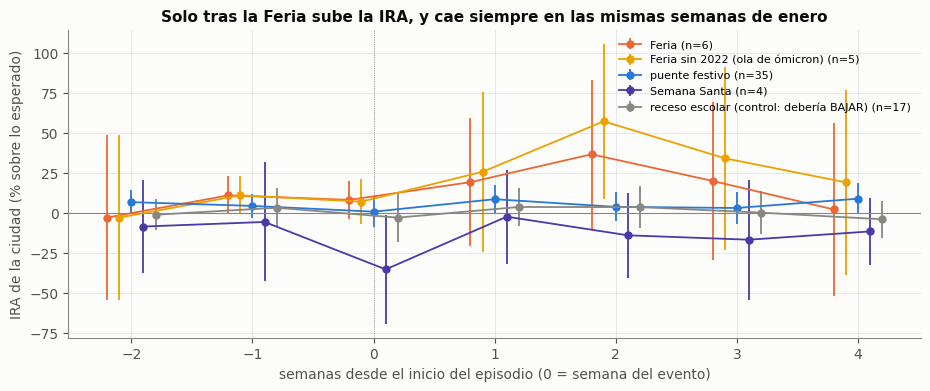

,episodios,sem -2,sem -1,sem +0,sem +1,sem +2,sem +3,sem +4
evento,,,,,,,,
Feria,6,-2.9,11.0,8.2,19.3,36.7,20.0,2.2
Feria sin 2022 (ola de ómicron),5,-2.9,11.0,7.1,25.7,57.3,34.2,19.1
puente festivo,35,6.8,4.5,0.8,8.6,3.9,3.1,8.9
Semana Santa,4,-8.4,-5.6,-35.2,-2.3,-13.9,-16.7,-11.5
receso escolar (control: debería BAJAR),17,-1.1,3.3,-2.9,3.8,3.7,0.2,-3.9


In [3]:
A = anomalia(ira)
A = A[~A.index.to_series().between(*COVID)]
def eventos_semana(senal):
    s = a_semana(senal).reindex(A.index).fillna(0) > 0
    ini = s & ~s.shift(1, fill_value=False)             # primera semana de cada episodio
    return list(s[ini].index)
feria_eps = eventos_semana(feria)
grupos = {"Feria": feria_eps, "Feria sin 2022 (ola de ómicron)": [f for f in feria_eps if f.year != 2022], "puente festivo": eventos_semana(puente), "Semana Santa": eventos_semana(semana_santa),
          "receso escolar (control: debería BAJAR)": eventos_semana(receso)}
K = range(-2, 5)
fig, ax = plt.subplots(figsize=(11, 4)); filas = []
for i, (nom, fechas) in enumerate(grupos.items()):
    M = pd.DataFrame({f: [A.get(f + pd.Timedelta(weeks=k), np.nan) for k in K] for f in fechas}, index=list(K))
    m = M.mean(axis=1); e = 1.96 * M.std(axis=1) / np.sqrt(M.notna().sum(axis=1))
    ax.errorbar(np.array(list(K)) + (i - 2) * .1, 100 * (np.exp(m) - 1), yerr=100 * e, fmt="o-", ms=5, lw=1.3,
                color=[NARANJA, AMARILLO, AZUL, VIOLETA, MUDO][i], label=f"{nom} (n={M.shape[1]})")
    filas.append({"evento": nom, "episodios": M.shape[1], **{f"sem {k:+d}": round(100 * (np.exp(m[k]) - 1), 1) for k in K}})
ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
ax.set_xlabel("semanas desde el inicio del episodio (0 = semana del evento)"); ax.set_ylabel("IRA de la ciudad (% sobre lo esperado)")
ax.set_title("Solo tras la Feria sube la IRA, y cae siempre en las mismas semanas de enero"); ax.legend(fontsize=8); plt.show()
pd.DataFrame(filas).set_index("evento")

**Lectura.** Cada línea es el promedio de la anomalía de IRA alrededor del inicio de los episodios de un tipo de
evento, con su intervalo al 95 %:

| Evento | episodios | +1 semana | +2 semanas | +3 semanas |
|---|---|---|---|---|
| Feria | 6 | +19 % | +37 % | +20 % |
| Feria sin 2022 (ómicron) | 5 | +26 % | +57 % | +34 % |
| Puente festivo | 35 | +9 % | +4 % | +3 % |
| Semana Santa | 4 | −2 % | −14 % | −17 % |
| Receso escolar | 17 | +4 % | +4 % | 0 % |

- Tras la Feria la IRA sube y, sin 2022, sube más: la ola no es la de ómicron. Pero no se puede atribuir a la
  Feria. Cae siempre en las mismas semanas de enero, así que no existe un enero sin Feria con que compararla, y
  el calendario de eventos solo la marca desde 2020 mientras el año de referencia incluye 2015-2019. Lo que sí
  queda es que en los años recientes enero trae una ola respiratoria, que el cuaderno 10 ve también en el
  hospital (respiratorio de enero a 1,26 de la media), justo después de la temporada decembrina y del regreso
  de vacaciones. Qué parte pesa en cada una no se puede separar con estos datos.
- Los puentes festivos no mueven la IRA: de +3 a +9 % con 35 episodios y sin forma de contagio.
- Semana Santa baja la IRA registrada: −35 % esa misma semana y de −14 a −17 % después.
- El receso escolar, medido desde su inicio, no baja la IRA. En el cuaderno 09 sí lo hacía (−0,20 en la misma
  semana), porque allí se miraban las semanas de receso y aquí el inicio de cada receso. El efecto de cerrar
  colegios no es robusto al método.

La Semana Santa merece una segunda mirada por su mecanismo. Si la IRA registrada dependiera de la consulta de
quien necesita la constancia para faltar al trabajo, bajaría en cualquier semana con menos días laborables. Se
contrasta con el número de festivos de la semana.

In [4]:
# Mecanismo de la consulta: un festivo quita un día laborable a la semana. Si la IRA registrada dependiera de la
# consulta por incapacidad, las semanas con festivo mostrarían menos casos.
fest = a_semana(calc.es_festivo.fillna(0)).reindex(A.index)
ss = (a_semana(semana_santa).reindex(A.index) > 0).astype(float)
dfw = pd.DataFrame({"y": A, "festivos": fest, "semana_santa": ss}).dropna()
filas = []
for desde in ["2015", "2022"]:
    dd = dfw.loc[desde:]
    m = sm.OLS(dd.y, sm.add_constant(dd[["festivos", "semana_santa"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    for v, et in [("festivos", "por cada festivo de la semana"), ("semana_santa", "semana con Semana Santa")]:
        e, ic = pct(m.params[v], m.bse[v])
        filas.append({"desde": desde, "semanas": len(dd), "efecto sobre la IRA": et, "efecto %": e, "IC95": ic, "p": round(m.pvalues[v], 2)})
dd = dfw[dfw.semana_santa == 0]
m = sm.OLS(dd.y, sm.add_constant(dd[["festivos"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
e, ic = pct(m.params["festivos"], m.bse["festivos"])
filas.append({"desde": "2015, sin Semana Santa", "semanas": len(dd), "efecto sobre la IRA": "por cada festivo de la semana", "efecto %": e, "IC95": ic, "p": round(m.pvalues["festivos"], 2)})
pd.DataFrame(filas)

,desde,semanas,efecto sobre la IRA,efecto %,IC95,p
0,2015,478,por cada festivo de la semana,-0.2,[-7.3; +7.4],0.96
1,2015,478,semana con Semana Santa,-21.9,[-39.9; +1.7],0.07
2,2022,209,por cada festivo de la semana,-1.0,[-7.7; +6.2],0.78
3,2022,209,semana con Semana Santa,-20.5,[-38.7; +3.0],0.08
4,"2015, sin Semana Santa",471,por cada festivo de la semana,4.1,[-3.4; +12.2],0.29


**Lectura.** Un festivo adicional no mueve la IRA registrada: −0,2 % [−7,3; +7,4] en 478 semanas desde 2015 y
−1,0 % [−7,7; +6,2] en las 209 de 2022-2025. Quitando Semana Santa el coeficiente es +4,1 % [−3,4; +12,2]. La
semana con Semana Santa sí cae alrededor de un 22 % (−21,9 % [−39,9; +1,7], p = 0,07), con un intervalo que
roza el cero porque solo hay cuatro episodios en el periodo sin COVID.

La diferencia entre las dos cifras indica que la baja de Semana Santa no se explica por quitar un día
laborable (un festivo suelto no deja marca): la ciudad se vacía una semana entera y los servicios reducen la
atención. Es menos consulta registrada y no necesariamente menos contagio. El diseño tiene un límite: la IRA
semanal de las instituciones mezcla consultas de todos los días de la semana, y no puede distinguir si un
paciente enfermó en día laborable o de fin de semana. El mecanismo de la incapacidad exige la serie diaria del
hospital y no se pone a prueba aquí.

---
# 3. El frío y la humedad empujan la IRA, sobre todo en la temporada de lluvias

Mecanismo: un mes más frío o más húmedo de lo normal favorece la transmisión respiratoria con un rezago de días
a semanas. Si el contagio escolar fuera el canal principal, el efecto debería ser mayor con los colegios
abiertos (la suma de factores). Se regresa la anomalía semanal de la IRA sobre la anomalía media de temperatura
(con signo invertido) y de humedad de las 1 a 5 semanas previas, separando las semanas de colegio abierto de las
de receso, con errores robustos a la autocorrelación (HAC). La ventana es 2022-2025, donde hay clima y recesos
oficiales. El efecto se expresa por desviación típica de la exposición, porque una desviación típica del frío
medio de un mes es solo 0,33 °C: por grado el mismo coeficiente sería unas tres veces mayor y no debe leerse
como un efecto de 25 a 30 %.

In [5]:
T = anomalia(a_semana(cl.temp_media_consenso, "mean").loc["2020":])
H = anomalia(a_semana(cl.humedad_consenso, "mean").loc["2020":])
d = pd.DataFrame({"ira": anomalia(ira.loc["2022":"2025"]),
                  "frio_1a5": -pd.concat([T.shift(k) for k in range(1, 6)], axis=1).mean(axis=1),
                  "humedo_1a5": pd.concat([H.shift(k) for k in range(1, 6)], axis=1).mean(axis=1),
                  "abierto": (a_semana(receso).reindex(idx).fillna(0) < 3).astype(float)}).dropna()
res = []
for var in ["frio_1a5", "humedo_1a5"]:
    xs = (d[var] - d[var].mean()) / d[var].std()          # 1 unidad = 1 desviacion tipica
    X = pd.DataFrame({"c": 1.0, "x": xs, "abierto": d.abierto, "x_por_abierto": xs * d.abierto})
    m = sm.OLS(d.ira, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    b, V = m.params, m.cov_params()
    for nom, w in [("receso", np.array([0, 1, 0, 0])), ("colegio abierto", np.array([0, 1, 0, 1]))]:
        est, se = w @ b.values, np.sqrt(w @ V.values @ w)
        res.append({"factor (1 sd, semanas 1-5 previas)": {"frio_1a5": "frío", "humedo_1a5": "humedad"}[var], "cuando": nom,
                    "efecto sobre IRA %": round(100 * (np.exp(est) - 1), 1), "IC95": f"[{100*(np.exp(est-1.96*se)-1):+.1f}; {100*(np.exp(est+1.96*se)-1):+.1f}]"})
    res.append({"factor (1 sd, semanas 1-5 previas)": {"frio_1a5": "frío", "humedo_1a5": "humedad"}[var], "cuando": "diferencia (interacción)",
                "efecto sobre IRA %": round(100 * b["x_por_abierto"], 1), "IC95": f"p = {m.pvalues['x_por_abierto']:.2f}"})
print(f"{len(d)} semanas; con colegio abierto: {int(d.abierto.sum())}; 1 desviación típica de frío (5 semanas previas) = {d.frio_1a5.std():.2f} °C")
R = pd.DataFrame(res)
R

209 semanas; con colegio abierto: 160; 1 desviación típica de frío (5 semanas previas) = 0.33 °C


,"factor (1 sd, semanas 1-5 previas)",cuando,efecto sobre IRA %,IC95
0,frío,receso,9.9,[+2.1; +18.2]
1,frío,colegio abierto,7.6,[+2.7; +12.6]
2,frío,diferencia (interacción),-2.1,p = 0.57
3,humedad,receso,9.7,[+3.1; +16.6]
4,humedad,colegio abierto,6.8,[+2.3; +11.5]
5,humedad,diferencia (interacción),-2.7,p = 0.45


**Lectura.** El frío y la humedad empujan la IRA con los colegios abiertos y en receso. Efecto de una
desviación típica, 2022-2025:

| | Receso | Colegio abierto | Diferencia |
|---|---|---|---|
| Frío | +9,9 % [+2,1; +18,2] | +7,6 % [+2,7; +12,6] | −2,1 % (p = 0,57) |
| Humedad | +9,7 % [+3,1; +16,6] | +6,8 % [+2,3; +11,5] | −2,7 % (p = 0,45) |

Una racha de un mes más fría o más húmeda de lo normal va seguida de un 7 a un 10 % más de IRA en la ciudad, dentro de
lo que la literatura publica (2 a 10 %) para el efecto del clima sobre las urgencias. La suma colegio ×
frío no aparece: el frío pesa igual con y sin colegios. El contagio relevante en Manizales quizá no es solo
el escolar, o las 49 semanas de receso son pocas para ver la diferencia.

Un cambio de 0,3 °C no puede ser la causa directa de un 8-10 % de IRA, lo que sugiere que la temperatura
actúa como marcador de otra cosa (humedad, nubosidad, masas de aire). El cuaderno 17 llega al mismo punto con
otras variables: un mes lluvioso, nublado, húmedo y con poco sol trae un 6-7 % más de IRA entre 1 y 5 semanas
después (lluvia de 28 días +7,0 %, horas de sol −7,0 %, 53 pruebas sobreviven a la corrección por pruebas
múltiples), con 13 años de datos.

El split por colegio y el split por temporada se solapan, porque los colegios están abiertos casi toda la
temporada de lluvias. Se prueba ahora la segunda partición, que es la que sugiere la literatura de Bogotá
(el VSR sube en marzo-mayo, la primera temporada de lluvias; Rodriguez-Martinez 2015, Gamba-Sanchez 2016), y
una segunda forma de la exposición: el cambio, es decir, el enfriamiento de las semanas 1-2 contra las
semanas 3-6 previas. Es la pregunta de la transición frente al nivel. La definición de la temporada (marzo-mayo
y octubre-noviembre) viene de esa literatura y no se fijó antes de mirar los datos de este cuaderno: es
exploratoria, con una sola partición.

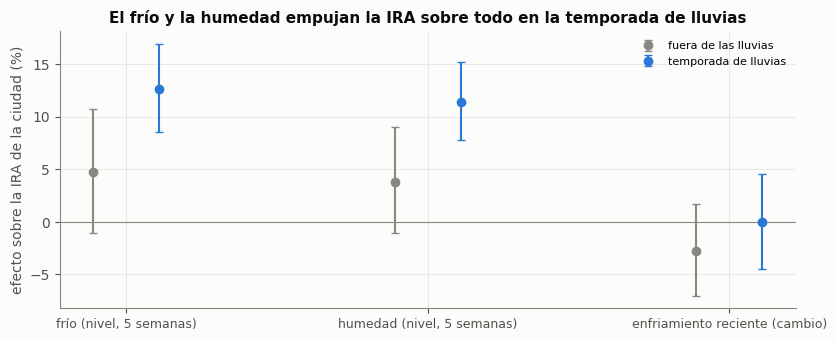

209 semanas, de ellas 87 en temporada de lluvias; correlación nivel-cambio de frío = 0.06
nivel y cambio juntos (coeficiente log, p): {'nivel': (0.08, 0.0), 'cambio': (-0.018, 0.2)}


,exposición (1 sd),cuándo,efecto sobre IRA %,IC95
0,"frío (nivel, 5 semanas)",fuera de las lluvias,4.7,[-1.0; +10.7]
1,"frío (nivel, 5 semanas)",temporada de lluvias,12.6,[+8.5; +16.9]
2,"frío (nivel, 5 semanas)",diferencia (interacción),7.3,p = 0.032
3,"humedad (nivel, 5 semanas)",fuera de las lluvias,3.8,[-1.1; +9.0]
4,"humedad (nivel, 5 semanas)",temporada de lluvias,11.4,[+7.7; +15.2]
5,"humedad (nivel, 5 semanas)",diferencia (interacción),7.0,p = 0.019
6,enfriamiento reciente (cambio),fuera de las lluvias,-2.8,[-7.0; +1.7]
7,enfriamiento reciente (cambio),temporada de lluvias,-0.0,[-4.5; +4.6]
8,enfriamiento reciente (cambio),diferencia (interacción),2.7,p = 0.407


In [6]:
# La misma regresión, partida ahora por temporada del año en lugar de por colegio, y con una segunda forma de la
# exposición: el CAMBIO (semanas 1-2 contra semanas 3-6 previas) en vez del nivel medio de 5 semanas.
dd = pd.DataFrame({"ira": anomalia(ira.loc["2022":"2025"]),
                   "frio": -pd.concat([T.shift(k) for k in range(1, 6)], axis=1).mean(axis=1),
                   "humedad": pd.concat([H.shift(k) for k in range(1, 6)], axis=1).mean(axis=1),
                   "cambio_frio": -(pd.concat([T.shift(k) for k in (1, 2)], axis=1).mean(axis=1)
                                    - pd.concat([T.shift(k) for k in range(3, 7)], axis=1).mean(axis=1))}).dropna()
dd["lluvias"] = dd.index.month.isin([3, 4, 5, 10, 11]).astype(float)       # marzo-mayo y octubre-noviembre
filas = []
for var, et in [("frio", "frío (nivel, 5 semanas)"), ("humedad", "humedad (nivel, 5 semanas)"), ("cambio_frio", "enfriamiento reciente (cambio)")]:
    xs = (dd[var] - dd[var].mean()) / dd[var].std()
    X = pd.DataFrame({"c": 1.0, "x": xs, "ll": dd.lluvias, "x_ll": xs * dd.lluvias})
    m = sm.OLS(dd.ira, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4}); b, V = m.params, m.cov_params()
    for nom, w in [("fuera de las lluvias", np.array([0, 1, 0, 0])), ("temporada de lluvias", np.array([0, 1, 0, 1]))]:
        est, se = w @ b.values, np.sqrt(w @ V.values @ w)
        e, ic = pct(est, se)
        filas.append({"exposición (1 sd)": et, "cuándo": nom, "efecto sobre IRA %": e, "IC95": ic, "_lo": 100*(np.exp(est-1.96*se)-1), "_hi": 100*(np.exp(est+1.96*se)-1)})
    filas.append({"exposición (1 sd)": et, "cuándo": "diferencia (interacción)", "efecto sobre IRA %": round(100 * b["x_ll"], 1), "IC95": f"p = {m.pvalues['x_ll']:.3f}", "_lo": np.nan, "_hi": np.nan})
R2 = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
g = R2[R2["cuándo"].ne("diferencia (interacción)")].reset_index(drop=True)
for i, (et, sub) in enumerate(g.groupby("exposición (1 sd)", sort=False)):
    for j, (cu, col) in enumerate([("fuera de las lluvias", MUDO), ("temporada de lluvias", AZUL)]):
        r = sub[sub["cuándo"].eq(cu)].iloc[0]
        ax.errorbar(i + (j - .5) * .22, r["efecto sobre IRA %"], yerr=[[r["efecto sobre IRA %"] - r["_lo"]], [r["_hi"] - r["efecto sobre IRA %"]]],
                    fmt="o", color=col, capsize=3, label=cu if i == 0 else None)
ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(3), g["exposición (1 sd)"].unique(), fontsize=9)
ax.set_ylabel("efecto sobre la IRA de la ciudad (%)"); ax.legend(fontsize=8)
ax.set_title("El frío y la humedad empujan la IRA sobre todo en la temporada de lluvias"); plt.show()
print(f"{len(dd)} semanas, de ellas {int(dd.lluvias.sum())} en temporada de lluvias; correlación nivel-cambio de frío = {dd.frio.corr(dd.cambio_frio):.2f}")
xs1 = (dd.frio - dd.frio.mean()) / dd.frio.std(); xs2 = (dd.cambio_frio - dd.cambio_frio.mean()) / dd.cambio_frio.std()
mj = sm.OLS(dd.ira, pd.DataFrame({"c": 1.0, "nivel": xs1, "cambio": xs2})).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print("nivel y cambio juntos (coeficiente log, p):", {k: (round(mj.params[k], 3), round(mj.pvalues[k], 2)) for k in ["nivel", "cambio"]})
R2.drop(columns=["_lo", "_hi"])

**Lectura.** El efecto del nivel de frío y de humedad se concentra en la temporada de lluvias: el frío da
+12,6 % [+8,5; +16,9] en lluvias contra +4,7 % [−1,0; +10,7] fuera de ellas (interacción p = 0,032), y la
humedad +11,4 % [+7,7; +15,2] contra +3,8 % [−1,1; +9,0] (p = 0,019). Son 87 de las 209 semanas. Es coherente con
el pico del VSR de marzo-mayo descrito en Bogotá, y fuera de la temporada la misma desviación pesa la mitad o menos. La condición cambia el tamaño del efecto: el
promedio de 7 a 10 % de la tabla anterior mezcla dos regímenes.

El cambio reciente no aporta lo que aporta el nivel. El enfriamiento de las semanas 1-2 contra las 3-6 da
−2,8 % [−7,0; +1,7] fuera de las lluvias y 0,0 % [−4,5; +4,6] en ellas (p de la interacción 0,41). Con nivel y
cambio en el mismo modelo, el nivel mantiene su efecto (coeficiente 0,08, p < 0,01) y el cambio no (−0,018,
p = 0,20); la correlación entre los dos es 0,06, así que no se estorban. A escala semanal y con esta
temperatura, lo que mueve la IRA es el nivel sostenido durante un mes y no la transición. La literatura sí
describe la transición como factor independiente a 0-21 días (Zhan 2017; Wang 2022), con el aumento brusco de
temperatura como el dañino; el diseño de aquí solo mide el enfriamiento, y el tamaño de la muestra no permite
afirmar que la transición no importe. El cuaderno 17 llega al mismo punto con otra construcción: los cambios
bruscos y la transición de seco a lluvioso sobreviven menos que los niveles de 28 días.

Límite: dos factores correlacionados entre sí (frío y humedad) y una partición escogida con ayuda de la
literatura no equivalen a dos hallazgos independientes. Se toma como una pista de condición para el modelo, no
como un resultado cerrado.

---
# 4. La lluvia reduce las riñas, y la violencia intrafamiliar no responde al clima

Mecanismo: la lluvia saca a la gente de la calle y reduce la exposición a la riña. Se ajusta un Poisson diario de lesiones personales, violencia intrafamiliar y lesiones de tránsito
(Policía) sobre la lluvia del día y la anomalía de temperatura, con el control de calendario del cuaderno 09:
día de la semana, festivo, quincena, noches festivas y año. Periodo 2020-2026, sin las cuarentenas.

In [7]:
D = pd.DataFrame(index=dias)
D["lluvia_sd"] = ((cl.precip_consenso_mm - cl.precip_consenso_mm.mean()) / cl.precip_consenso_mm.std()).reindex(dias)
tz = cl.temp_media_consenso; tz = (tz - tz.groupby(tz.index.month).transform("mean")) / tz.std()
D["temp_anom_sd"] = tz.reindex(dias)
D["festivo"] = calc.es_festivo.fillna(0); D["quincena"] = calc.es_quincena.fillna(0)
md_ = pd.Series(list(zip(dias.month, dias.day)), index=dias)
D["noche_festiva"] = md_.isin([(12, 7), (12, 8), (12, 24), (12, 25), (12, 31), (1, 1)]).astype(float)
ok = D.notna().all(axis=1) & ~dias.to_series().between("2020-03-01", "2021-06-30").values & (dias >= "2020-01-01")
X = pd.concat([D[ok], pd.get_dummies(pd.Index(dias[ok].dayofweek), prefix="d", drop_first=True).set_index(dias[ok]).astype(float),
               pd.get_dummies(pd.Index(dias[ok].year), prefix="a", drop_first=True).set_index(dias[ok]).astype(float)], axis=1)
X.insert(0, "c", 1.0)
filas = []
for col, nom in [("lesiones_personales", "lesiones personales"), ("violencia_intrafamiliar", "violencia intrafamiliar"),
                 ("lesiones_transito", "lesiones de tránsito")]:
    m = sm.GLM(seg[col][ok], X, family=sm.families.Poisson()).fit(cov_type="HC0")
    for v, et in [("lluvia_sd", "lluvia (+1 sd)"), ("temp_anom_sd", "más cálido que lo normal (+1 sd)")]:
        b, s = m.params[v], m.bse[v]
        filas.append({"serie": nom, "factor": et, "efecto %": round(100 * (np.exp(b) - 1), 1),
                      "IC95": f"[{100*(np.exp(b-1.96*s)-1):+.1f}; {100*(np.exp(b+1.96*s)-1):+.1f}]"})
print(f"{int(ok.sum())} días")
pd.DataFrame(filas)

1942 días


,serie,factor,efecto %,IC95
0,lesiones personales,lluvia (+1 sd),-5.7,[-10.1; -1.1]
1,lesiones personales,más cálido que lo normal (+1 sd),4.5,[-0.2; +9.4]
2,violencia intrafamiliar,lluvia (+1 sd),-1.2,[-5.9; +3.8]
3,violencia intrafamiliar,más cálido que lo normal (+1 sd),-0.3,[-5.7; +5.3]
4,lesiones de tránsito,lluvia (+1 sd),-1.1,[-4.9; +2.8]
5,lesiones de tránsito,más cálido que lo normal (+1 sd),0.1,[-4.1; +4.5]


**Lectura.** Las lesiones personales bajan un 5,7 % por desviación típica de lluvia [−10,1; −1,1], con el
calendario ya descontado. Los días más cálidos de lo normal suben un 4,5 % [−0,2; +9,4], en el borde. La
violencia intrafamiliar no responde al clima (−1,2 % con la lluvia, −0,3 % con la temperatura): ocurre dentro
de la casa. El tránsito registrado tampoco responde, igual que en el cuaderno 07. Es coherente con el cuaderno
19, donde las violencias de salud responden poco al clima (una prueba sobreviviente de 63, la semana cálida y
bochornosa), y con la idea de que la lluvia actúa sobre la exposición en la calle y no sobre la violencia
doméstica.

Un matiz de medición: la lluvia diaria del clima unificado es ruidosa (el pluviómetro válido cubre una parte de
los días), de modo que el efecto medido tiende a subestimar el de la lluvia real sobre las riñas. La
pregunta que queda es si el efecto depende del tipo de día: el calendario fija cuándo hay riñas (las lesiones
personales promedian 1,53 por día laborable y 2,33 por día no laborable), y la lluvia podría pesar más cuando la
calle está llena.

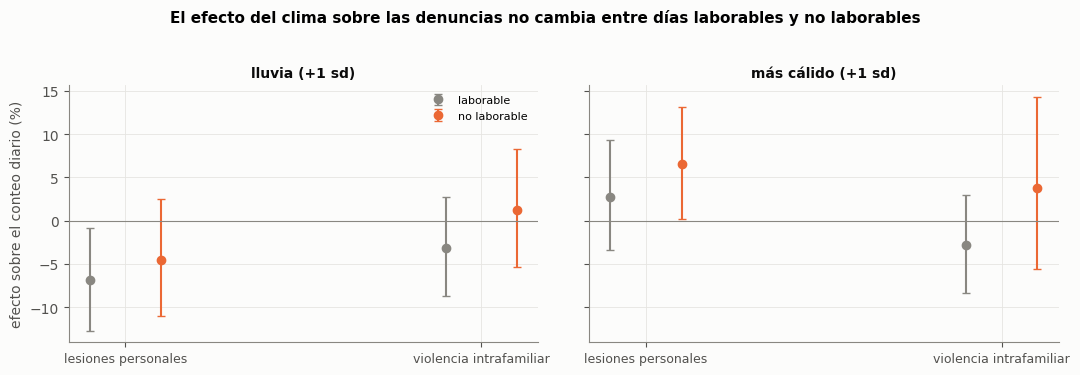

,serie,factor,día,efecto %,IC95,p de la diferencia,media diaria
0,lesiones personales,lluvia (+1 sd),laborable,-6.9,[-12.7; -0.8],,1.53
1,lesiones personales,lluvia (+1 sd),no laborable,-4.5,[-11.0; +2.5],0.59,2.33
2,lesiones personales,más cálido (+1 sd),laborable,2.8,[-3.4; +9.3],,1.53
3,lesiones personales,más cálido (+1 sd),no laborable,6.5,[+0.2; +13.2],0.39,2.33
4,violencia intrafamiliar,lluvia (+1 sd),laborable,-3.1,[-8.7; +2.8],,1.65
5,violencia intrafamiliar,lluvia (+1 sd),no laborable,1.2,[-5.4; +8.3],0.33,1.76
6,violencia intrafamiliar,más cálido (+1 sd),laborable,-2.8,[-8.4; +3.0],,1.65
7,violencia intrafamiliar,más cálido (+1 sd),no laborable,3.8,[-5.6; +14.3],0.21,1.76
8,homicidio,lluvia (+1 sd),laborable,9.9,[-13.2; +39.2],,0.08
9,homicidio,lluvia (+1 sd),no laborable,-24.2,[-44.0; +2.6],0.05,0.15


In [8]:
# Mismo modelo, con el efecto del clima partido por tipo de día: laborable frente a no laborable (fin de semana
# o festivo). Mecanismo: la lluvia saca a la gente de la calle sobre todo cuando hay fiesta, que es cuando hay riñas.
X = X.copy()
nolab = ((dias[ok].dayofweek >= 5) | (D.festivo[ok] == 1)).astype(float)
for v in ["lluvia_sd", "temp_anom_sd"]:
    X[v + "_nolab"] = X[v] * nolab.values
filas = []
for col, nom in [("lesiones_personales", "lesiones personales"), ("violencia_intrafamiliar", "violencia intrafamiliar"),
                 ("homicidio", "homicidio"), ("lesiones_transito", "lesiones de tránsito")]:
    m = sm.GLM(seg[col][ok], X, family=sm.families.Poisson()).fit(cov_type="HC0")
    nm = list(m.params.index)
    for v, et in [("lluvia_sd", "lluvia (+1 sd)"), ("temp_anom_sd", "más cálido (+1 sd)")]:
        for cu, extra in [("laborable", None), ("no laborable", v + "_nolab")]:
            w = np.zeros(len(nm)); w[nm.index(v)] = 1
            if extra: w[nm.index(extra)] = 1
            est, se = w @ m.params.values, np.sqrt(w @ m.cov_params().values @ w)
            e, ic = pct(est, se)
            filas.append({"serie": nom, "factor": et, "día": cu, "efecto %": e, "IC95": ic,
                          "p de la diferencia": round(m.pvalues[v + "_nolab"], 2) if extra else "",
                          "media diaria": round(seg[col][ok][nolab.values == (cu == "no laborable")].mean(), 2)})
RD = pd.DataFrame(filas)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, fac in zip(axes, ["lluvia (+1 sd)", "más cálido (+1 sd)"]):
    sub = RD[RD.factor.eq(fac) & RD.serie.isin(["lesiones personales", "violencia intrafamiliar"])]
    for i, (ser, s2) in enumerate(sub.groupby("serie", sort=False)):
        for j, (cu, col) in enumerate([("laborable", MUDO), ("no laborable", NARANJA)]):
            r = s2[s2["día"].eq(cu)].iloc[0]; lo, hi = [float(x) for x in r.IC95.strip("[]").split(";")]
            ax.errorbar(i + (j - .5) * .2, r["efecto %"], yerr=[[r["efecto %"] - lo], [hi - r["efecto %"]]], fmt="o", color=col, capsize=3,
                        label=cu if i == 0 else None)
    ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(2), ["lesiones personales", "violencia intrafamiliar"], fontsize=9); ax.set_title(fac, fontsize=10)
axes[0].set_ylabel("efecto sobre el conteo diario (%)"); axes[0].legend(fontsize=8)
fig.suptitle("El efecto del clima sobre las denuncias no cambia entre días laborables y no laborables", fontsize=11, fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()
RD

**Lectura.** El efecto de la lluvia sobre las lesiones personales es −6,9 % [−12,7; −0,8] en día laborable y
−4,5 % [−11,0; +2,5] en día no laborable; la diferencia no se distingue (p = 0,59). El calor da +2,8 % y
+6,5 % [+0,2; +13,2] (p = 0,39). En la violencia intrafamiliar ningún efecto se separa de cero en ninguno de
los dos tipos de día. La hipótesis de que la lluvia vacíe más la calle los días de fiesta no recibe respaldo:
con 1.942 días el diseño no tiene potencia para detectar diferencias pequeñas entre tipos de día, y tampoco hay
indicio de una grande.

Hay dos coeficientes aislados que no se interpretan. El homicidio da −24,2 % con lluvia en día no laborable
(p de la diferencia 0,05), pero con 0,08 y 0,15 homicidios por día el intervalo va de −44 % a +3 %, y
la tabla contiene ocho contrastes de interacción; el calor sobre las lesiones de tránsito en día no laborable (+5,9 %, p = 0,04) es
una de ellas y no tiene un mecanismo que lo sostenga. Con ocho contrastes, uno o dos con p cerca de 0,05 son lo que
da el azar.

---
# 5. Los eventos de la ciudad casi no dejan huella en las denuncias

Mecanismo: las fiestas concentran gente y alcohol. En Colombia el domingo concentra el 20,4 % de los
homicidios y el fin de semana el 38,8 % de las lesiones de violencia interpersonal (Forensis 2023), y en el
Carnaval de Barranquilla la probabilidad diaria de un homicidio de hombre se multiplica por 2,3 (Guarin-Ardila
2019). Se prueba si los eventos de Manizales con fuente (Feria, Festival de Teatro, aniversario de la ciudad y
Semana Santa) dejan marca en las denuncias, con el mismo Poisson diario y el mismo control de calendario. Cada
evento entra como un indicador de sus días de celebración.

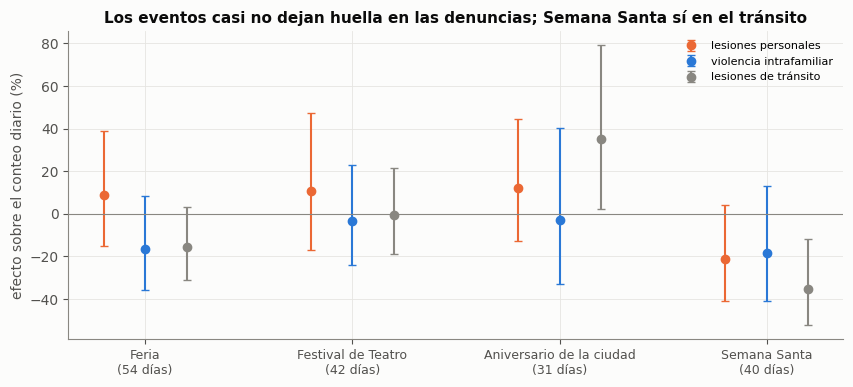

,evento,días,serie,efecto %,IC95
0,Feria,54,lesiones personales,8.8,[-14.9; +39.0]
1,Feria,54,violencia intrafamiliar,-16.6,[-35.9; +8.5]
2,Feria,54,lesiones de tránsito,-15.5,[-31.0; +3.3]
3,Festival de Teatro,42,lesiones personales,10.6,[-16.9; +47.1]
4,Festival de Teatro,42,violencia intrafamiliar,-3.3,[-24.0; +23.0]
5,Festival de Teatro,42,lesiones de tránsito,-0.7,[-18.9; +21.5]
6,Aniversario de la ciudad,31,lesiones personales,12.2,[-12.8; +44.4]
7,Aniversario de la ciudad,31,violencia intrafamiliar,-3.1,[-32.9; +40.1]
8,Aniversario de la ciudad,31,lesiones de tránsito,35.3,[+2.3; +79.1]
9,Semana Santa,40,lesiones personales,-21.3,[-40.7; +4.4]


In [9]:
# Eventos de la ciudad y seguridad. Poisson diario con el mismo control de calendario (día de la semana, festivo,
# quincena, noches festivas y año). Cada evento entra como un indicador de los días en que se celebró.
Xe = X.drop(columns=[c for c in X.columns if c in ("lluvia_sd", "temp_anom_sd") or c.endswith("_nolab")])
def dias_de(nombre):
    e = eventos[ok_ev & eventos.nombre_evento.eq(nombre)]
    return marcar(e.fecha_inicio, e.fecha_fin)
filas = []
for nombre, et in [("Feria de Manizales", "Feria"), ("Festival Internacional de Teatro de Manizales", "Festival de Teatro"),
                   ("Aniversario de Manizales", "Aniversario de la ciudad"), ("Semana Santa", "Semana Santa")]:
    mk = dias_de(nombre)
    Xi = Xe.copy(); Xi["evento"] = mk[ok].values
    for col, nom in [("lesiones_personales", "lesiones personales"), ("violencia_intrafamiliar", "violencia intrafamiliar"), ("lesiones_transito", "lesiones de tránsito")]:
        m = sm.GLM(seg[col][ok], Xi, family=sm.families.Poisson()).fit(cov_type="HC0")
        e, ic = pct(m.params["evento"], m.bse["evento"])
        filas.append({"evento": et, "días": int(Xi.evento.sum()), "serie": nom, "efecto %": e, "IC95": ic,
                      "_lo": 100*(np.exp(m.params["evento"]-1.96*m.bse["evento"])-1), "_hi": 100*(np.exp(m.params["evento"]+1.96*m.bse["evento"])-1)})
RE = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(10, 4)); cols = {"lesiones personales": NARANJA, "violencia intrafamiliar": AZUL, "lesiones de tránsito": MUDO}
for i, (et, sub) in enumerate(RE.groupby("evento", sort=False)):
    for j, (_, r) in enumerate(sub.iterrows()):
        ax.errorbar(i + (j - 1) * .2, r["efecto %"], yerr=[[r["efecto %"] - r._lo], [r._hi - r["efecto %"]]], fmt="o", color=cols[r.serie], capsize=3,
                    label=r.serie if i == 0 else None)
ax.axhline(0, color=MUDO, lw=.8); ax.set_xticks(range(4), [f"{e}\n({int(s.días.iloc[0])} días)" for e, s in RE.groupby("evento", sort=False)], fontsize=9)
ax.set_ylabel("efecto sobre el conteo diario (%)"); ax.legend(fontsize=8)
ax.set_title("Los eventos casi no dejan huella en las denuncias; Semana Santa sí en el tránsito"); plt.show()
RE.drop(columns=["_lo", "_hi"])

**Lectura.** Los intervalos son anchos y casi todos cruzan el cero. La Feria (54 días en seis años) da +8,8 %
en lesiones personales [−14,9; +39,0], −16,6 % en violencia intrafamiliar [−35,9; +8,5] y −15,5 % en tránsito
[−31,0; +3,3]; el Festival de Teatro y el aniversario tampoco muestran un efecto en las lesiones personales
(+10,6 % y +12,2 %, intervalos de unos 60 puntos de ancho). Dos efectos sí se separan de cero: Semana Santa
reduce las lesiones de tránsito un 35,1 % [−52,3; −11,8], coherente con la ciudad vacía de la semana
(la IRA registrada también cae), y el aniversario de la ciudad las sube un 35,3 % [+2,3; +79,1], sin un
mecanismo claro. Con 12 pruebas, una o dos fuera del cero entran en lo esperable por azar, y lo que se repite es el signo negativo de Semana Santa en las tres series (de −18 a −35 %), aunque solo el tránsito
se separa de cero.

Los eventos no están marcados con la finura que pide el mecanismo: la noche, no el día, es cuando se bebe, y
el conteo diario de la Policía no distingue horas. El diseño es sensible a cambios de varias decenas de
puntos y no a los de 10 o 15 que sí darían una fiesta. Tampoco se puede separar la Feria del tramo de enero
en que cae (noches festivas, Reyes, regreso de vacaciones). Lo que se afirma es que, con este instrumento,
no se detecta un efecto de los eventos locales sobre las denuncias; no se afirma que no exista.

---
# 6. El intento de suicidio tiene su propio año, al revés de la fiesta

Se mira el intento de suicidio (SIVIGILA 356) y las intoxicaciones (365) según el mes del año y según los días
festivos y de quincena de la semana. Es semanal, 2016-2025 sin COVID. El perfil del año es la media de la
razón entre cada semana y la media de su año.

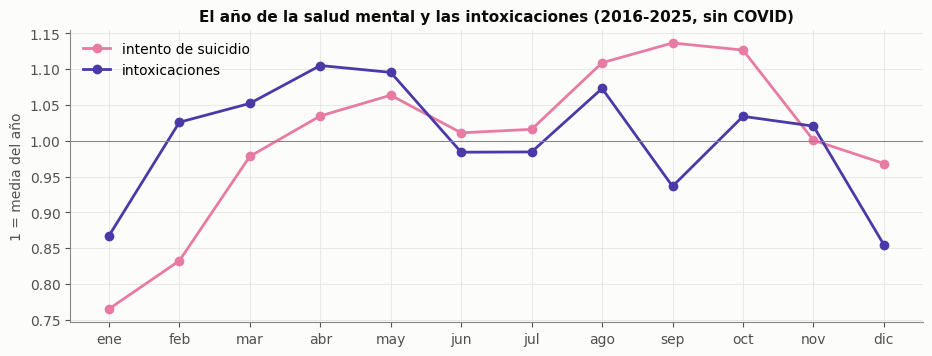

fecha_inicio_semana,ene,feb,mar,abr,may,jun,jul,ago,sep,oct,nov,dic
intento de suicidio,0.77,0.83,0.98,1.03,1.06,1.01,1.02,1.11,1.14,1.13,1.00,0.97
intoxicaciones,0.87,1.03,1.05,1.11,1.10,0.98,0.98,1.07,0.94,1.03,1.02,0.85


,serie,por cada día de,efecto %,IC95
0,intento de suicidio,festivos,7.4,[-2.1; +17.9]
1,intento de suicidio,quincena,4.1,[-4.3; +13.4]
2,intoxicaciones,festivos,-1.1,[-10.6; +9.4]
3,intoxicaciones,quincena,-4.2,[-13.0; +5.5]


In [10]:
W = pd.DataFrame({"intento de suicidio": ev(356), "intoxicaciones": ev(365)})
W = W[~W.index.to_series().between(*COVID)].loc["2016":"2025"]
W["festivos"] = a_semana(calc.es_festivo.fillna(0)).reindex(W.index)
W["quincena"] = a_semana(calc.es_quincena.fillna(0)).reindex(W.index)
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ax = plt.subplots(figsize=(11, 3.8)); perfil = {}
for c, col in [("intento de suicidio", MAGENTA), ("intoxicaciones", VIOLETA)]:
    s = W[c]; rel = s / s.groupby(s.index.year).transform("mean")
    p = rel.groupby(rel.index.month).mean(); perfil[c] = p.round(2)
    ax.plot(p.index, p.values, marker="o", color=col, lw=2, label=c)
ax.axhline(1, color=MUDO, lw=.8); ax.set_xticks(range(1, 13), meses); ax.set_ylabel("1 = media del año"); ax.legend()
ax.set_title("El año de la salud mental y las intoxicaciones (2016-2025, sin COVID)"); plt.show()
filas = []
for c in ["intento de suicidio", "intoxicaciones"]:
    X = pd.concat([pd.DataFrame({"c": 1.0, "festivos": W.festivos, "quincena": W.quincena}, index=W.index),
                   pd.get_dummies(pd.Index(W.index.year), prefix="a", drop_first=True).set_index(W.index).astype(float)], axis=1)
    m = sm.GLM(W[c], X, family=sm.families.Poisson()).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    for v in ["festivos", "quincena"]:
        b, s = m.params[v], m.bse[v]
        filas.append({"serie": c, "por cada día de": v, "efecto %": round(100 * (np.exp(b) - 1), 1),
                      "IC95": f"[{100*(np.exp(b-1.96*s)-1):+.1f}; {100*(np.exp(b+1.96*s)-1):+.1f}]"})
display(pd.DataFrame(perfil).rename(index=dict(enumerate(meses, 1))).T)
pd.DataFrame(filas)

**Lectura.** El gráfico muestra la razón mensual con 1 = media del año:

| | ene | feb | ago | sep | oct | dic |
|---|---|---|---|---|---|---|
| Intento de suicidio | 0,77 | 0,83 | 1,11 | 1,14 | 1,13 | 0,97 |
| Intoxicaciones | 0,87 | 1,03 | 1,07 | 0,94 | 1,03 | 0,85 |

- Los intentos de suicidio bajan en enero-febrero y suben en agosto-octubre, que son meses sin fiestas. Los
  días festivos (+7,4 % por día [−2,1; +17,9]) y la quincena (+4,1 % [−4,3; +13,4]) no tienen un efecto claro:
  los intervalos cruzan el cero. El patrón estacional existe en esta serie; la revisión de literatura hecha para
  el entorno no incluyó un estudio que lo contraste, y con estos datos no se puede decir si es un rasgo de
  Manizales o de la notificación.
- Las intoxicaciones notificadas bajan en diciembre y enero aunque se bebe más. El alcohol no se notifica como
  intoxicación, así que esto no lo contradice.

---
# 7. El ENSO es contexto de fondo y no precede a la salud de la ciudad con una señal clara

Mecanismo: El Niño reduce la lluvia y calienta los Andes colombianos, y La Niña hace lo contrario con efectos
más marcados (Poveda 2004; Poveda y Mesa 1997); el cuaderno 09 mide ENSO → temperatura en +0,49. De ahí se
esperaría menos IRA con El Niño (la IRA responde al frío y a la humedad) y más diarrea unos meses después
(en Lima, la diarrea sube con la temperatura de El Niño; Checkley 2000, aunque allí El Niño calienta y moja).
Se cruza, por mes, el ONI con la anomalía de IRA y de EDA de la ciudad de 0 a 6 meses después, 2015-2019 y
2022-2025.

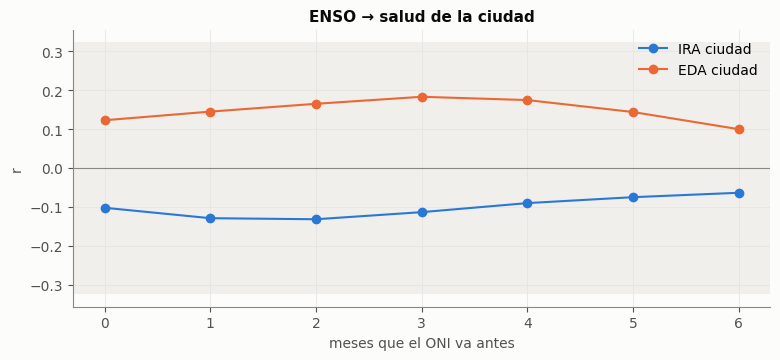

,0 meses,1 meses,2 meses,3 meses,4 meses,5 meses,6 meses,meses
serie,,,,,,,,
IRA ciudad,-0.10,-0.13,-0.13,-0.11,-0.09,-0.07,-0.06,110
EDA ciudad,0.12,0.15,0.17,0.18,0.17,0.14,0.10,110


In [11]:
o = oni.set_index(oni.fecha.dt.to_period("M"))["oni"]
def mensual(s):
    m = s.groupby(s.index.to_period("M")).sum()
    m = m[~((m.index >= pd.Period("2020-03", "M")) & (m.index <= pd.Period("2021-12", "M")))]
    m = np.log(m.replace(0, np.nan)).dropna()
    m = m - m.groupby(m.index.year).transform("mean")
    return m - m.groupby(m.index.month).transform("mean")
series = {"IRA ciudad": mensual(np.exp(ira).loc["2015":"2025"]), "EDA ciudad": mensual(ev(998, "casos_eda_total").loc["2015":"2025"])}
fig, ax = plt.subplots(figsize=(9, 3.6)); filas = []
for i, (nom, s) in enumerate(series.items()):
    rs = [s.corr(o.shift(k).reindex(s.index)) for k in range(0, 7)]
    ax.plot(range(7), rs, marker="o", color=[AZUL, NARANJA][i], label=nom)
    filas.append({"serie": nom, **{f"{k} meses": round(r, 2) for k, r in enumerate(rs)}, "meses": len(s)})
n = min(len(s) for s in series.values()); um = 1.96 / np.sqrt(n / 3)       # aproximado: autocorrelacion alta del ONI
ax.axhspan(-um, um, color="#f0efec", lw=0); ax.axhline(0, color=MUDO, lw=.8)
ax.set_xlabel("meses que el ONI va antes"); ax.set_ylabel("r"); ax.set_title("ENSO → salud de la ciudad"); ax.legend(); plt.show()
pd.DataFrame(filas).set_index("serie")

**Lectura.** El gráfico muestra la correlación mensual del ONI con la anomalía a cada rezago (110 meses). La
IRA da −0,10 a −0,13, en la dirección esperada: El Niño, más cálido, va con un poco menos de IRA. La EDA da
+0,15 a +0,18 a 2-4 meses. Ninguna pasa el umbral aproximado (~0,32), que es alto porque el ONI cambia muy
despacio. Para ver si el índice continuo oculta un efecto de fase, se repite con El Niño y La Niña como
estados (ONI de dos meses antes ≥ +0,5 o ≤ −0,5).

In [12]:
# El mismo cruce con las FASES del ENSO (ONI de dos meses antes >= +0,5 / <= -0,5) en lugar del índice continuo.
oni2 = o.shift(2)
filas = []
for nom, s in series.items():
    on = oni2.reindex(s.index)
    X = pd.DataFrame({"c": 1.0, "El Niño": (on >= .5).astype(float), "La Niña": (on <= -.5).astype(float)})
    m = sm.OLS(s, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    for v in ["El Niño", "La Niña"]:
        e, ic = pct(m.params[v], m.bse[v])
        filas.append({"serie": nom, "fase": v, "meses en la fase": int(X[v].sum()), "efecto %": e, "IC95": ic})
pd.DataFrame(filas)

,serie,fase,meses en la fase,efecto %,IC95
0,IRA ciudad,El Niño,43,-1.7,[-7.8; +4.8]
1,IRA ciudad,La Niña,22,1.6,[-9.2; +13.8]
2,EDA ciudad,El Niño,43,8.6,[+0.4; +17.4]
3,EDA ciudad,La Niña,22,7.3,[-5.1; +21.2]


**Lectura.** Los meses en cada fase son 43 de El Niño y 22 de La Niña, de pocos episodios (en la ventana con
datos de salud, cuatro de El Niño y cinco de La Niña, cuaderno 20). La IRA no responde a ninguna fase: El Niño
−1,7 % [−7,8; +4,8], La Niña +1,6 % [−9,2; +13,8]. La EDA sube con El Niño +8,6 % [+0,4; +17,4], en el borde
del intervalo y en la dirección que sugiere el índice continuo, y con La Niña +7,3 % [−5,1; +21,2]. Con
cuatro episodios, un intervalo que apenas excluye el cero no es evidencia de que El Niño mueva la diarrea
de Manizales: coincide con la dirección de Lima pero allí el mecanismo (calor y lluvia) no es el de los Andes
colombianos.

El cuaderno 20 usa otro periodo (2012-2024), otra unidad (desviaciones típicas del índice de cada familia) y una
tendencia lineal en lugar del año fijo. Allí La Niña sube la violencia, la salud mental y la varicela por
encima de la corrección por pruebas múltiples, y la respiratoria (+0,29) y la digestiva (+0,17) en la misma
dirección sin pasar el umbral; El Niño no mueve ninguna familia. Aquí La Niña tiene el signo positivo en las
dos series, sin significancia. Ambos cuadernos coinciden en que el ENSO no deja una señal firme sobre la IRA
y no coinciden en cuál fase mueve la EDA, de modo que la digestiva queda sin concluir. El ENSO se trata como
contexto: actúa a través de la temperatura y la lluvia, que son las que sí se miden.

---
# 8. La lluvia que llega tras un periodo seco no mueve la EDA de la ciudad

Mecanismo: la lluvia intensa tras un periodo seco arrastra contaminación acumulada al agua de beber y sube la
diarrea, mientras que la misma lluvia tras un periodo húmedo no lo hace (Carlton 2014, Ecuador rural: IRR 1,39
tras sequía y 0,74 tras un periodo húmedo, con el historial de 8 semanas). Es la evidencia publicada más
cercana a «importa la transición, no el nivel». Se mide la anomalía de EDA de la ciudad contra la lluvia
estandarizada de las semanas 1-2 previas, separando las semanas cuyo periodo previo (semanas 3-8) fue seco
(lluvia bajo lo normal de la semana del año) de las de periodo húmedo. Solo hay clima unificado desde 2020, así
que la ventana es 2022-2025.

In [13]:
# Lluvia reciente según el historial: la misma lluvia debería pesar distinto tras un periodo seco que tras uno húmedo.
eda = ev(998, "casos_eda_total")
edaA = anomalia(np.log(eda.replace(0, np.nan)).dropna())
P = a_semana(cl.precip_consenso_mm.loc["2020":], "sum")
Pn = (P - P.groupby(P.index.isocalendar().week.values).transform("mean")); Pn = Pn / Pn.std()
reciente = pd.concat([Pn.shift(k) for k in (1, 2)], axis=1).mean(axis=1)            # semanas 1-2 previas
previo = pd.concat([Pn.shift(k) for k in range(3, 9)], axis=1).mean(axis=1)         # semanas 3-8 previas
d = pd.DataFrame({"eda": edaA, "reciente": reciente, "previo": previo}).loc["2022":"2025"].dropna()
d = d[~d.index.to_series().between(*COVID)]
d["seco_previo"] = (d.previo < 0).astype(float)
xs = (d.reciente - d.reciente.mean()) / d.reciente.std()
m = sm.OLS(d.eda, pd.DataFrame({"c": 1.0, "x": xs, "seco": d.seco_previo, "x_seco": xs * d.seco_previo})).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
b, V = m.params, m.cov_params(); filas = []
for nom, w in [("tras un periodo húmedo", np.array([0, 1, 0, 0])), ("tras un periodo seco", np.array([0, 1, 0, 1]))]:
    est, se = w @ b.values, np.sqrt(w @ V.values @ w); e, ic = pct(est, se)
    filas.append({"lluvia de las semanas 1-2 previas (+1 sd)": nom, "efecto sobre la EDA %": e, "IC95": ic})
filas.append({"lluvia de las semanas 1-2 previas (+1 sd)": "diferencia (interacción)", "efecto sobre la EDA %": round(100 * b["x_seco"], 1), "IC95": f"p = {m.pvalues['x_seco']:.2f}"})
print(f"{len(d)} semanas (2022-2025, sin COVID); {int(d.seco_previo.sum())} con periodo previo seco")
pd.DataFrame(filas)

209 semanas (2022-2025, sin COVID); 70 con periodo previo seco


,lluvia de las semanas 1-2 previas (+1 sd),efecto sobre la EDA %,IC95
0,tras un periodo húmedo,-0.5,[-4.1; +3.2]
1,tras un periodo seco,0.8,[-3.6; +5.5]
2,diferencia (interacción),1.4,p = 0.63


**Lectura.** La lluvia reciente no mueve la EDA ni tras un periodo húmedo (−0,5 % [−4,1; +3,2]) ni tras uno seco
(+0,8 % [−3,6; +5,5]); la diferencia es 1,4 puntos (p = 0,63) sobre 209 semanas, 70 de ellas con periodo previo
seco. Los intervalos descartan efectos del tamaño que reporta Carlton (+39 %). En el estudio de Ecuador tratar el agua de consumo atenuó el efecto, y la EDA de la
ciudad mezcla causas virales, bacterianas y parasitarias, de modo que un efecto menor era esperable, pero no uno nulo con un
intervalo tan estrecho.

Esto no contradice el cuaderno 19. Allí la EDA sube un 15,7 % por desviación típica cuanto más tiempo pasa sin
una semana muy lluviosa (12 de 63 pruebas sobreviven a la corrección). La señal está en la duración de la
sequía y no en el regreso de la lluvia: la exposición relevante parece ser la racha seca, no el evento
de lluvia. Eso es lo que se debe llevar al modelo, con la advertencia de que la EDA solo llega con los
microdatos, unos ocho meses tarde, y no sirve como predictor operativo.

---
# 9. Coincidencias y diferencias con los cuadernos 17, 19 y 20

Los cruces de este cuaderno se repiten con otras construcciones en los cuadernos de clima, familias de
enfermedad y regímenes. La tabla pone cada cruce con la cifra de cada lado.

| Cruce | Este cuaderno | Cuaderno 17, 19 o 20 | Lectura |
|---|---|---|---|
| Clima → IRA de la ciudad | Frío +7,6 a +9,9 % y humedad +6,8 a +9,7 % por desviación típica, 5 semanas | Mes lluvioso, nublado y húmedo: +6-7 % a 1-5 semanas (17); 53 pruebas sobreviven | Coinciden en tamaño y rezago; el mes manda sobre la semana |
| Cambio brusco → IRA | Enfriamiento reciente −2,8 % y 0,0 %, no significativo | Los cambios bruscos y la transición seco-lluvioso sobreviven menos que los niveles (17) | Coinciden: a escala semanal el nivel pesa más que la transición |
| Racha seca → IRA | Frío y humedad del mes empujan la IRA | Una racha seca larga baja la IRA un 9,5 % a 3 semanas (19) | Coinciden: es el mismo mecanismo visto desde el otro lado |
| Clima → violencia | Lluvia −5,7 % en lesiones personales; la violencia intrafamiliar no responde | Violencias de salud: 1 de 63 pruebas (19) | No chocan: son series distintas (Policía diaria frente a SIVIGILA semanal) |
| Clima → EDA | La lluvia tras sequía no mueve la EDA (+0,8 % [−3,6; +5,5]) | Más días sin lluvia fuerte, +15,7 % por desviación típica (19) | Se refieren a exposiciones distintas: la racha seca, no el regreso de la lluvia |
| ENSO → salud | IRA −1,7 % (El Niño) y +1,6 % (La Niña), sin significancia; EDA +8,6 % con El Niño, en el borde | La Niña sube violencias, salud mental y varicela; El Niño no mueve ninguna familia (20) | Coinciden en que no hay señal firme sobre la IRA; discrepan en la fase de la EDA |
| Clima → hospital | No se mide aquí | El clima mueve el triage total entre 1,5 y 2,4 % por desviación típica, y esos efectos no son los de la IRA (correlación −0,35 entre los efectos sobre una y otro) (17) | Solo la IRA de la ciudad responde con tamaño |

Los cuadernos 17 y 19 trabajan con 2012-2024 y con un índice del clima completo; este usa el clima unificado
de 2022-2025 y una sola exposición por cruce. La coincidencia entre construcciones distintas es lo que da
confianza en el cruce frío-humedad → IRA.

---
# 10. Conclusiones y límites

**Conclusiones.**

1. El frío y la humedad del último mes empujan la IRA de la ciudad entre un 7 y un 10 % por desviación típica
   en 2022-2025, con y sin colegios abiertos (diferencia p = 0,57 y 0,45). Es la única cadena clima → contagio
   con tamaño, mecanismo y respaldo en los cuadernos 17 y 19.
2. La condición que modifica el efecto es la temporada: en marzo-mayo y octubre-noviembre el frío da +12,6 % y la
   humedad +11,4 %; fuera de ella, +4,7 % y +3,8 %, sin significancia (interacción p = 0,032 y 0,019). Es una
   pista exploratoria con una partición.
3. A escala semanal importa el nivel sostenido, no el cambio: el enfriamiento reciente no aporta (p = 0,20)
   cuando el nivel ya está en el modelo.
4. Enero trae una ola respiratoria en los años recientes (+19 a +57 % a 1-3 semanas del inicio de la Feria),
   que no se puede atribuir a la Feria, a la temporada decembrina ni al regreso de vacaciones por separado.
   Los puentes no mueven la IRA, y Semana Santa la baja un 22 % por menos consulta registrada.
5. La lluvia reduce las lesiones personales un 5,7 %, con el calendario descontado, sin diferencia clara entre
   días laborables y no laborables; la violencia intrafamiliar no responde al clima.
6. Los eventos locales no dejan una huella detectable en las denuncias, salvo la baja de Semana Santa en el
   tránsito (−35 %).
7. El intento de suicidio baja en enero-febrero (0,77-0,83) y sube en agosto-octubre (1,11-1,14).
8. El ENSO y la lluvia tras la sequía no mueven la IRA ni la EDA de la ciudad con una señal que supere el azar.
9. Policía y SIVIGILA solo se validan en tendencia; donde miden lo mismo basta una.

**Qué entra al repertorio del modelo y qué queda de contexto.** Entran el frío y la humedad del último mes
(con la temporada como condición), enero como periodo respiratorio y la lluvia con el calendario festivo para
lo que ocurre en la calle. Quedan como contexto, sin entrar: el ENSO, la salud mental, los puentes, los eventos
locales y las series de la Policía como predictor.

**Límites del análisis.**

- Todo es de la ciudad y no del hospital. La IRA de la ciudad no incluye la del hospital de referencia, y el
  cuaderno 17 muestra que solo ella responde con tamaño al clima; sobre el triage total el clima tiene efectos de 1,5-2,4 %, que no son los de la IRA diluida (correlación −0,35 entre los efectos sobre una y otro).
- El mecanismo de la incapacidad (enfermar en día laborable lleva a urgencias a pedir la constancia, y en fin
  de semana no necesariamente) no se puede poner a prueba con series semanales de la ciudad. Lo que se midió es
  que un festivo suelto no mueve la IRA registrada (−0,2 % [−7,3; +7,4]).
- La muestra efectiva es corta. La ventana de clima es 2022-2025 (209 semanas), con un residuo semanal muy
  autocorrelacionado; varios cruces parten de un número de episodios pequeño (cuatro Semana Santa,
  seis Ferias, 43 y 22 meses de ENSO).
- Los cruces con tipo de día, temporada e historial son exploratorios: cada uno hace dos o tres contrastes y,
  en la de día laborable, ocho, de modo que algún p cercano a 0,05 es esperable por azar.
- El clima observado no es el pronóstico; en operación se usaría el segundo, con otro error.
- El conteo diario de la Policía no distingue la hora, y los eventos se marcan por día, mientras el mecanismo
  operaría de noche.